**Prática de Segmentação de imagens**

In [4]:
# code here
import cv2
import matplotlib.pyplot as plt
import numpy as np

1) Faça a plotagem do histograma da imagem, observando o histograma, escolha um valor para definir um threshold

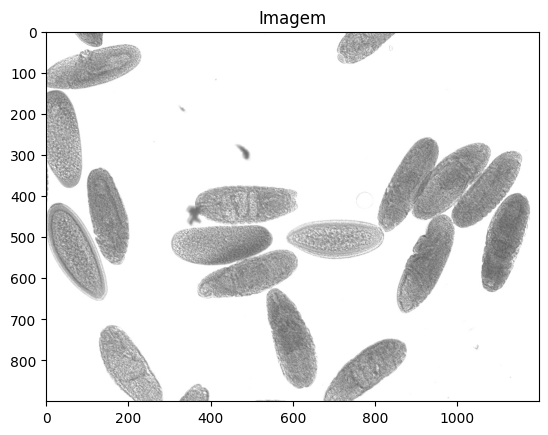

C:\Users\caioc\AppData\Local\Temp\ipykernel_6044\3916079832.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img1.ravel(), 256, [0,256])


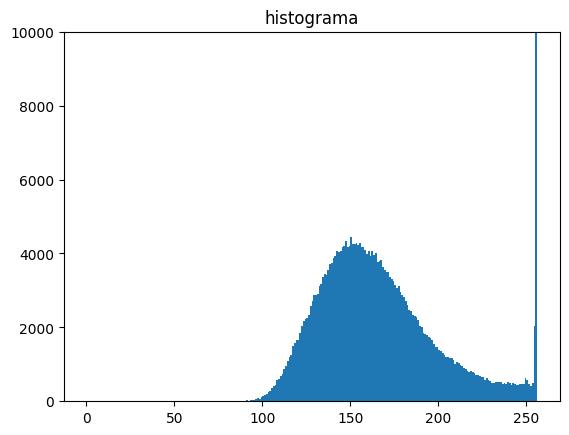

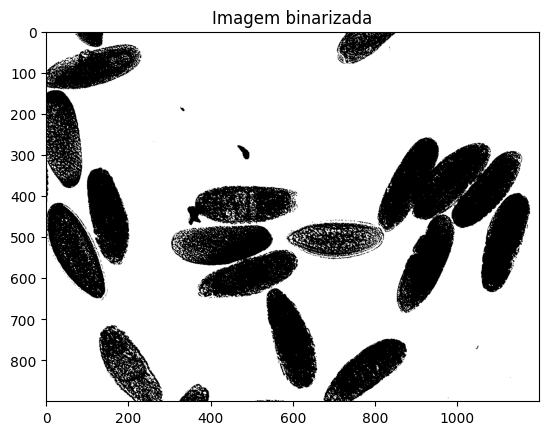

In [52]:
import cv2
import matplotlib.pyplot as plt

# ler imagem em escala de cinza
img1 = cv2.imread("insitu107595.jpg", cv2.IMREAD_GRAYSCALE)

# mostrar imagem
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title("Imagem")
plt.show()

# plotar histograma
plt.hist(img1.ravel(), 256, [0,256])
plt.ylim(0, 10000)
plt.title("histograma")
plt.show()

# threshold escolhido manualmente (exemplo)
T = 200

# aplicar limiarização
_, img_bin = cv2.threshold(img1, T, 255, cv2.THRESH_BINARY)

# mostrar resultado
plt.imshow(img_bin, cmap='gray')
plt.title("Imagem binarizada")
plt.show()


2)	Segmentação utilizando a técnica de Threshold Adaptativo (implementar o algortimo). Faça a aplicação do Threshold com e sem suavização prévia

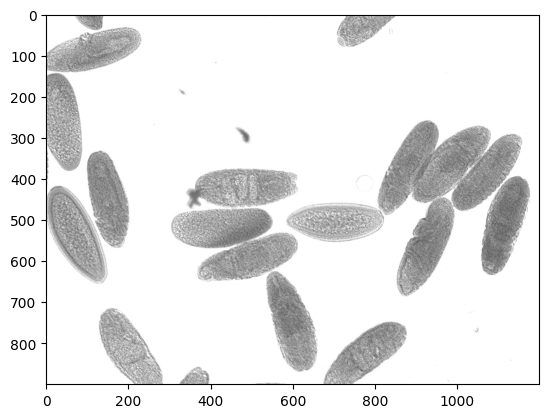

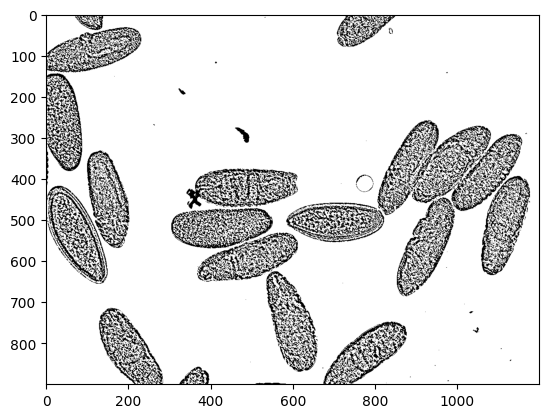

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread("insitu107595.jpg", cv2.IMREAD_GRAYSCALE)

plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.show()

def threshold_adaptativo(img, tam, c):
    h, w = img.shape
    out = np.zeros((h, w), dtype=np.uint8)
    r = tam // 2

    for i in range(h):
        for j in range(w):
            li = max(0, i - r)
            ls = min(h, i + r + 1)
            ci = max(0, j - r)
            cs = min(w, j + r + 1)

            janela = img[li:ls, ci:cs]
            media = np.mean(janela)

            if img[i, j] > media - c:
                out[i, j] = 255
            else:
                out[i, j] = 0

    return out

bin = threshold_adaptativo(img1, 15, 5)

plt.imshow(bin, cmap='gray', vmin=0, vmax=255)
plt.show()

3) Segmentação utilizando a técnica de Otsu (implementar) . Faça a aplicação do Threshold com e sem suavização prévia. Mostre um gráfico com o histograma juntamente com a variância entre classes (Exemplo: https://en.wikipedia.org/wiki/File:Otsu%27s_Method_Visualization.gif)

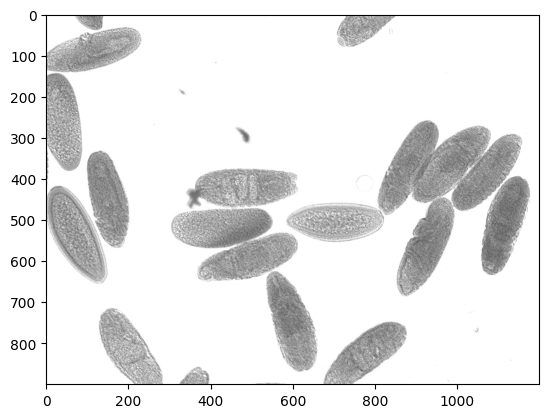

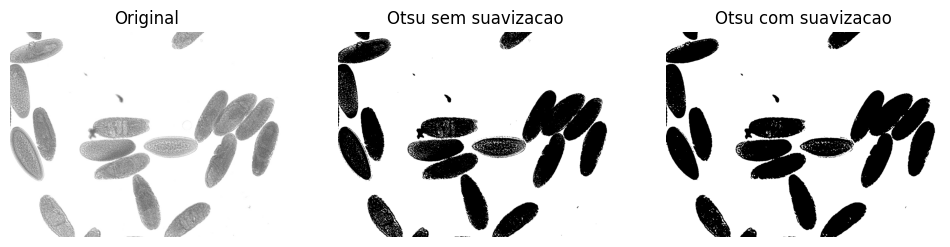

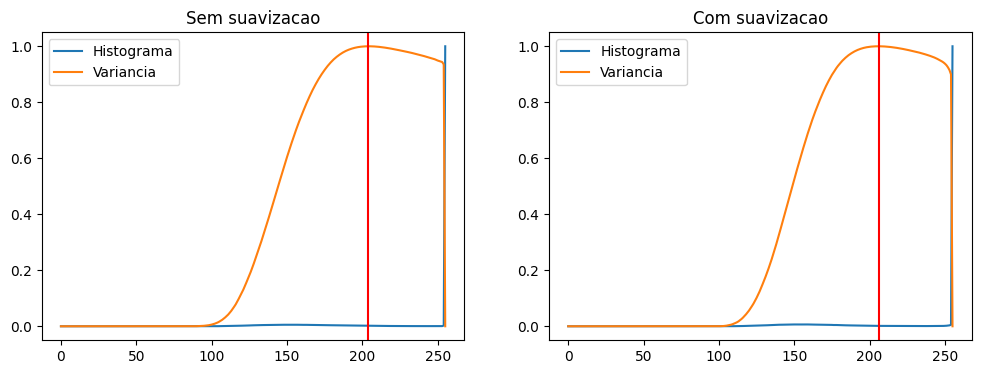

Threshold Otsu sem suavizacao: 204
Threshold Otsu com suavizacao: 206


In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img1 = cv2.imread("insitu107595.jpg", cv2.IMREAD_GRAYSCALE)

plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.show()

def otsu(img):
    hist = np.bincount(img.ravel(), minlength=256)
    p = hist / hist.sum()

    variancias = np.zeros(256)
    mg = 0
    for i in range(256):
        mg += i * p[i]

    w0 = 0
    m0 = 0

    for t in range(256):
        w0 += p[t]
        m0 += t * p[t]

        w1 = 1 - w0

        if w0 == 0 or w1 == 0:
            variancias[t] = 0
        else:
            mu0 = m0 / w0
            mu1 = (mg - m0) / w1
            variancias[t] = w0 * w1 * (mu0 - mu1) ** 2

    T = np.argmax(variancias)

    binaria = np.zeros(img.shape, dtype=np.uint8)
    binaria[img > T] = 255

    return T, binaria, hist, variancias

T1, bin1, hist1, var1 = otsu(img1)

img_suave = cv2.GaussianBlur(img1, (5,5), 0)
T2, bin2, hist2, var2 = otsu(img_suave)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(bin1, cmap='gray', vmin=0, vmax=255)
plt.title("Otsu sem suavizacao")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(bin2, cmap='gray', vmin=0, vmax=255)
plt.title("Otsu com suavizacao")
plt.axis("off")

plt.show()

# normalização para plot correto
hist1_n = hist1 / hist1.max()
hist2_n = hist2 / hist2.max()

var1_n = var1 / var1.max()
var2_n = var2 / var2.max()

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(hist1_n, label="Histograma")
plt.plot(var1_n, label="Variancia")
plt.axvline(T1, color='r')
plt.legend()
plt.title("Sem suavizacao")

plt.subplot(1,2,2)
plt.plot(hist2_n, label="Histograma")
plt.plot(var2_n, label="Variancia")
plt.axvline(T2, color='r')
plt.legend()
plt.title("Com suavizacao")

plt.show()

print("Threshold Otsu sem suavizacao:", T1)
print("Threshold Otsu com suavizacao:", T2)

In [ ]:
4)	Aplique o Otsu para a imagem HE.jpg, madrill.tiff e  Lenna.jpg (use antes a conversão da imagem para tons de cinza)

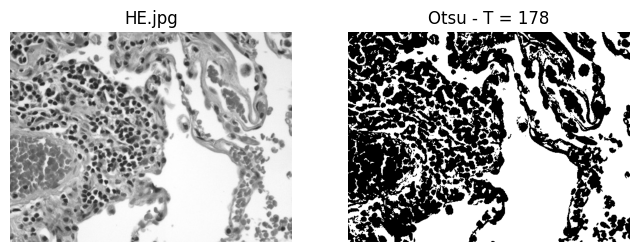

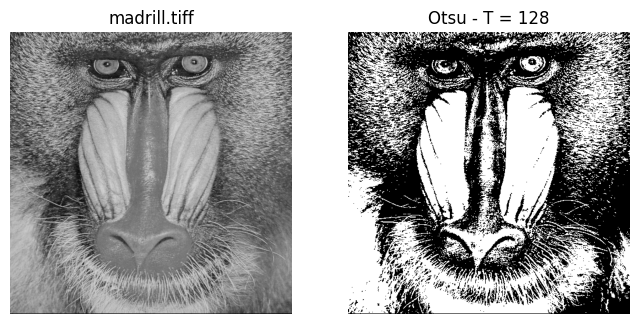

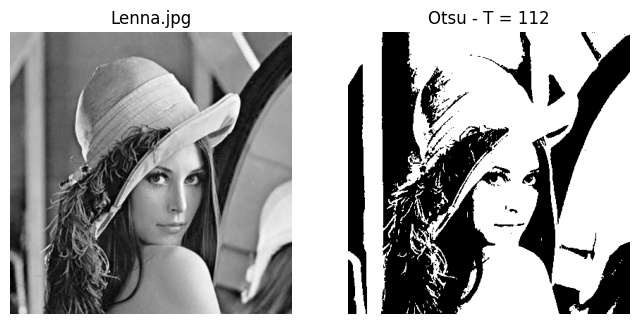

In [28]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def otsu(img):
    hist = np.bincount(img.ravel(), minlength=256)
    p = hist / hist.sum()

    variancias = np.zeros(256)
    mg = 0
    for i in range(256):
        mg += i * p[i]

    w0 = 0
    m0 = 0

    for t in range(256):
        w0 += p[t]
        m0 += t * p[t]

        w1 = 1 - w0

        if w0 == 0 or w1 == 0:
            variancias[t] = 0
        else:
            mu0 = m0 / w0
            mu1 = (mg - m0) / w1
            variancias[t] = w0 * w1 * (mu0 - mu1) ** 2

    T = np.argmax(variancias)

    binaria = np.zeros(img.shape, dtype=np.uint8)
    binaria[img > T] = 255

    return T, binaria

arquivos = ["HE.jpg", "madrill.tiff", "Lenna.jpg"]

for nome in arquivos:
    img = cv2.imread(nome, cv2.IMREAD_GRAYSCALE)

    T, binaria = otsu(img)

    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title(nome)
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(binaria, cmap='gray', vmin=0, vmax=255)
    plt.title("Otsu - T = " + str(T))
    plt.axis("off")

    plt.show()